Urządzenie: cpu

=== Test generatora ===
Oznaczone pozycje znaczników (kroki t): [10 17]
Wskazywane pozycje wartości (kroki t-8): [2 9]
Wartości tam znajdujące się: [0.9507 0.6011]
Obliczona suma (cel): 1.5518

--- Wyniki dla L = 50 (Baseline MSE = 0.1664) ---
SimpleRNN       | MSE: 0.1671 | Czas:   7.8s | Parametry: 1185
LSTM            | MSE: 0.1656 | Czas:  17.7s | Parametry: 4641
GRU             | MSE: 0.1408 | Czas:  21.7s | Parametry: 3489
Conv1D          | MSE: 0.1609 | Czas:  32.4s | Parametry: 25217

--- Wyniki dla L = 100 (Baseline MSE = 0.1751) ---
SimpleRNN       | MSE: 0.1764 | Czas:  14.6s | Parametry: 1185
LSTM            | MSE: 0.1749 | Czas:  32.6s | Parametry: 4641
GRU             | MSE: 0.1320 | Czas:  43.7s | Parametry: 3489
Conv1D          | MSE: 0.1731 | Czas:  57.4s | Parametry: 25217
SimpleRNN_h64   | MSE: 0.1893 | Czas:  46.0s | Parametry: 4417
Conv1D_d111     | MSE: 0.1758 | Czas:  53.7s | Parametry: 25217


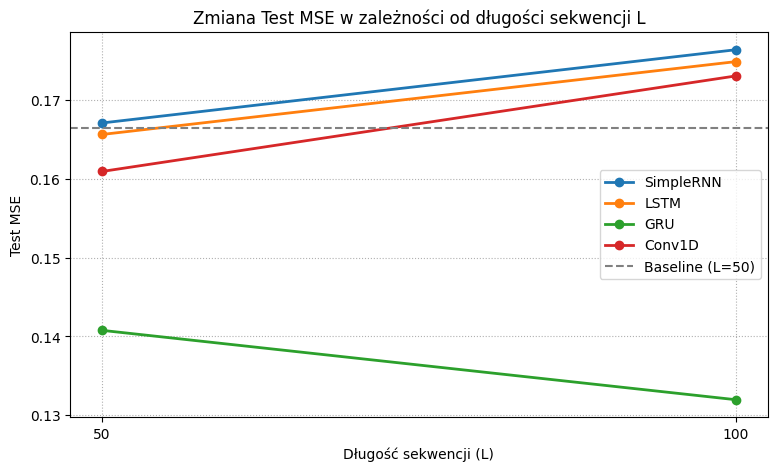

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)


def gen_delayed_adding(N, L, delay=8):
    """
    Generuje N przykładów o długości L.
    - Kanał 0: losowa wartość v_t z U[0, 1]
    - Kanał 1: znacznik m_t (0 lub 1) na pozycjach p >= delay
    - Cel (y): suma wartości v_{p - delay} dla dwóch oznaczonych p
    """
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), dtype=np.float32)
    y = np.zeros((N, 1), dtype=np.float32)

    for i in range(N):

        p = np.random.choice(np.arange(delay, L), 2, replace=False)
        mark[i, p, 0] = 1.0

        target_positions = p - delay
        y[i, 0] = val[i, target_positions, 0].sum()

    x = np.concatenate([val, mark], axis=2) # [N, L, 2]
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)


xx_sample, yy_sample = gen_delayed_adding(1, 20, delay=8)
pos_mark = np.where(xx_sample[0, :, 1].cpu().numpy() == 1)[0]
pos_val = pos_mark - 8

print("\n=== Test generatora ===")
print(f"Oznaczone pozycje znaczników (kroki t): {pos_mark + 1}")
print(f"Wskazywane pozycje wartości (kroki t-8): {pos_val + 1}")
print(f"Wartości tam znajdujące się: {xx_sample[0, pos_val, 0].cpu().numpy().round(4)}")
print(f"Obliczona suma (cel): {float(yy_sample[0, 0]):.4f}")


class RNNNet(nn.Module):
    def __init__(self, typ, hidden=32):
        super().__init__()
        self.rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ](2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class ConvNetCustom(nn.Module):
    def __init__(self, dilations=[1, 2, 4], ch=64):
        super().__init__()
        layers = []
        in_ch = 2
        for d in dilations:

            layers.append(nn.Conv1d(in_ch, ch, kernel_size=3, padding=d, dilation=d))
            layers.append(nn.ReLU())
            in_ch = ch
        self.net = nn.Sequential(*layers)
        self.fc = nn.Linear(ch, 1)
    def forward(self, x):

        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=5e-3, batch=128):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    N = Xtr.shape[0]


    if DEVICE == 'cuda': torch.cuda.synchronize()
    t0 = time.time()

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(N)
        for i in range(0, N, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            out = model(Xtr[idx])
            loss = loss_fn(out, Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

    if DEVICE == 'cuda': torch.cuda.synchronize()
    czas = time.time() - t0

    model.eval()
    with torch.no_grad():
        mse = loss_fn(model(Xte), Yte).item()

    return mse, czas


N_TR, N_TE = 4000, 800
results = {}

for L in [50, 100]:
    Xtr, Ytr = gen_delayed_adding(N_TR, L, delay=8)
    Xte, Yte = gen_delayed_adding(N_TE, L, delay=8)


    mean_y_tr = Ytr.mean().item()
    baseline_mse = torch.mean((Yte - mean_y_tr) ** 2).item()

    results[f"Baseline_L{L}"] = {'mse': baseline_mse, 'czas': 0.0, 'params': 0}
    print(f"\n--- Wyniki dla L = {L} (Baseline MSE = {baseline_mse:.4f}) ---")

    modele = {
        'SimpleRNN': RNNNet('RNN', hidden=32),
        'LSTM': RNNNet('LSTM', hidden=32),
        'GRU': RNNNet('GRU', hidden=32),
        'Conv1D': ConvNetCustom(dilations=[1, 2, 4], ch=64)
    }


    if L == 100:
        modele['SimpleRNN_h64'] = RNNNet('RNN', hidden=64)
        modele['Conv1D_d111'] = ConvNetCustom(dilations=[1, 1, 1], ch=64)

    for name, model in modele.items():
        mse, czas = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, batch=128)
        params = count_parameters(model)
        key = f"{name}_L{L}"
        results[key] = {'mse': mse, 'czas': czas, 'params': params}
        print(f"{name:15s} | MSE: {mse:.4f} | Czas: {czas:5.1f}s | Parametry: {params}")


plt.figure(figsize=(9, 5))
models_base = ['SimpleRNN', 'LSTM', 'GRU', 'Conv1D']
for m in models_base:
    mse_vals = [results[f"{m}_L50"]['mse'], results[f"{m}_L100"]['mse']]
    plt.plot([50, 100], mse_vals, marker='o', label=m, linewidth=2)

plt.axhline(results['Baseline_L50']['mse'], ls='--', color='gray', label='Baseline (L=50)')
plt.xticks([50, 100])
plt.xlabel('Długość sekwencji (L)')
plt.ylabel('Test MSE')
plt.title('Zmiana Test MSE w zależności od długości sekwencji L')
plt.legend()
plt.grid(True, ls=':')
plt.show()